Import libraries (pytorch, pandas, etc)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import math

Get MNIST dataset

In [46]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)


Might need to normalize dataset, remember that during debugging

In [47]:
images, labels = next(iter(train_loader))
print(images.shape)
print(images.min(), images.max())

RuntimeError: Broken pipe

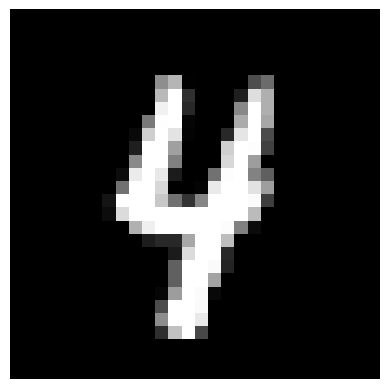

In [ ]:
plt.imshow(images[0, 0], cmap="gray")
plt.axis("off")
plt.show()

Creating beta schedule and calculating alpha

In [ ]:
T = 1000
beta_start = 1e-4
beta_end = 0.02
betas = torch.linspace(
    beta_start,
    beta_end,
    T
)
alphas = 1.0 - betas
alpha_time_t = torch.cumprod(alphas, dim=0)

Writing the "diffusion kernel", the calculation for how noisy the image should be at each timestep (starting with a linear schedule, so t will make the image noiser linearly)
Can change beta_start and beta_end to increase FID score if the forward pass introduces too much/too little noise at each step

In [ ]:
def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_alpha_time_t = torch.sqrt(alpha_time_t[t])
    sqrt_one_minus_alpha_time_t = torch.sqrt(1 - alpha_time_t[t])

    # Reshape so the values can be multiplied across the entire picture
    sqrt_alpha_time_t = sqrt_alpha_time_t[:, None, None, None]
    sqrt_one_minus_alpha_time_t = sqrt_one_minus_alpha_time_t[:, None, None, None]

    xt = (
        sqrt_alpha_time_t * x0
        + sqrt_one_minus_alpha_time_t * noise
    )

    return xt, noise

test forward passing using the scheduler

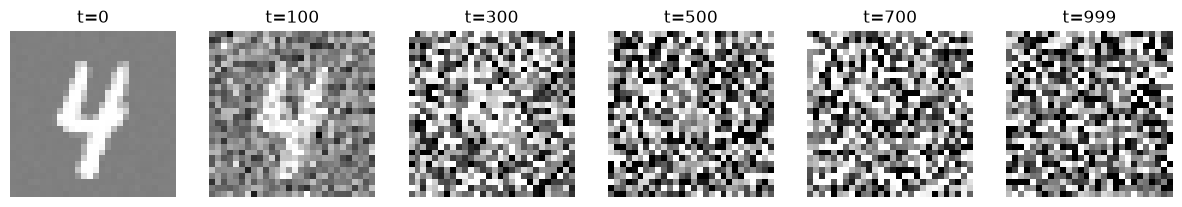

In [ ]:
x0 = images[0:1]

timesteps = [0, 100, 300, 500, 700, 999]

fig, axes = plt.subplots(1, len(timesteps), figsize=(15, 3))

for ax, t_value in zip(axes, timesteps):
    t = torch.tensor([t_value])

    xt, _ = q_sample(x0, t)

    ax.imshow(
        xt[0, 0].detach().cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t={t_value}")
    ax.axis("off")

plt.show()

Developing the UNET to predict the noise given a noisy image and the timestamp

Step 1: encode the timestep t as a sinusoidal embedding to give the model more information/context about the differences in t and let it learn better

In [ ]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):

        half_dim = self.dim // 2

        emb_scale = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(half_dim) * -emb_scale
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [torch.sin(emb), torch.cos(emb)],
            dim=1
        )

        return emb

we created the sin and cosine values using the scale (log(10000)/half_dim - 1), where the values end up being about evenly spaced out between 1 and 0 (1 -> 0.984 -> 0.972, etc)
then, put them all in a tensor, ran them through sine and cosine, then squashed them together using cat to get our final embedding, which is equivalent to a given t value, but with much more information so the machine can learn
The more dimensions are added to the embedding, the more the machine can see where t exactly falls since value 1 will change very quickly with t, value 2 will change slightly less quickly (since the logarithmic scale slightly decreases meaning the t value will have less effect on the final value)

In [ ]:
time_emb = SinusoidalTimeEmbedding(64)

t = torch.tensor([0, 100, 500, 999])

print(time_emb(t).shape)

torch.Size([4, 64])


In [ ]:
class block(nn.Module):
    def __init__(self, in_channels, out_channels, num_groups=8):
        super().__init__()
        self.normalize = nn.GroupNorm(num_groups, in_channels)
        self.convolute = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.act_func = nn.SiLU()

    def forward(self, x):
        x = self.normalize(x)
        x = self.act_func(x)
        x = self.convolute(x)
        return x


In [ ]:
class resnetblock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.mlp = nn.Linear(time_dim, out_channels)
        self.block1 = block(in_channels, out_channels)
        self.block2 = block(out_channels, out_channels)

        if in_channels != out_channels:
            self.residual = nn.Conv2d(in_channels, out_channels, kernel_size = 1)
        else: self.residual = nn.Identity()

    def forward(self, x, time_emb):
        h = self.block1(x)
        time_emb = self.mlp(time_emb)
        time_emb = time_emb[:, :, None, None]
        h = h + time_emb
        h = self.block2(h)

        return h + self.residual(x)

    

In [1]:
class UNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=64, time_dim=128):
        super().__init__()
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )
        #initial convolution to get 64 channels from the base 1 channel since the pictures are greyscale
        self.input_conv = nn.Conv2d(in_channels, base_channels, kernel_size=3, padding=1)

        #first downblock, convoluting and learning features while sending skip connection to upblocks
        self.downblock1 = resnetblock(base_channels, base_channels, time_dim)

        #first downsample, where number of channels increases for more feature learning and stride=2 to turn the 28 by 28 pictures into 14 by 14
        self.downsample1 = nn.Conv2d(base_channels, base_channels * 2, kernel_size = 4, stride=2, padding=1)

        self.downblock2 = resnetblock(base_channels * 2, base_channels * 2, time_dim)

        self.downsample2 = nn.Conv2d(base_channels * 2, base_channels * 4, kernel_size=4, stride=2, padding=1)

        self.bottleneck1 = resnetblock(base_channels * 4, base_channels * 4, time_dim)

        self.bottleneck2 = resnetblock(base_channels * 4, base_channels * 4, time_dim)

        #first upsample, reducing number of channels and increasing from 7 by 7 image to 14 by 14 using convtranspose2d
        self.upsample1 = nn.ConvTranspose2d(base_channels * 4, base_channels * 2, kernel_size = 4, stride=2, padding=1)

        self.upblock1 = resnetblock(base_channels * 2, base_channels * 2, time_dim)

        self.upsample2 = nn.ConvTranspose2d(base_channels * 2, base_channels, kernel_size=4, stride=2, padding=1)

        self.upblock2 = resnetblock(base_channels, base_channels, time_dim)

        self.output = nn.Conv2d(base_channels, in_channels, kernel_size=1)

        def forward(self, x, t):
            t_emb = self.time_embedding(t)
            x = self.input_conv(x)
            d1 = self.downblock1(x, t_emb)
            x = self.downsample1(d1)
            d2 = self.downblock2(x, t_emb)
            x = self.downsample2(d2)
            x = self.bottleneck1(x)
            x = self.bottleneck2(x)
            x = self.upsample1(x)
            x = torch.cat([x, d2], dim=1)
            u1 = self.upblock1(x, t_emb)
            x = self.upsample2(u1)
            x = torch.cat([x, d1], dim=1)
            u2 = self.upblock2(x, t_emb)
            return self.output(u2)
        

NameError: name 'nn' is not defined

Now, creating the resblock, which is used to process the image and identify the diffusion timestep based on the image. The process is: normalize the data, use a nonlinear activation function, convolute the data, add the timestep embedding, then repeat the first 3 steps. 

Now that the resblock has been built, we can build the model.
Architecture:
2 encoder blocks, 1 bottleneck, 2 decoder blocks
given the input and the time embedding, goes through the 2 down layers, the bottleneck, then the uplayers while concatenating to give one single output

In [ ]:
model = UNet()
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"{num_params:,} parameters")

4,789,057 parameters


In [ ]:
x = torch.randn(
    8, 1, 28, 28
)

t = torch.randint(
    0, T,
    (8,)
)

with torch.no_grad():
    output = model(x, t)

print(x.shape)
print(output.shape)

torch.Size([8, 1, 28, 28])
torch.Size([8, 1, 28, 28])


In [ ]:
x0, labels = next(iter(train_loader))


batch_size = x0.shape[0]

t = torch.randint(
    0,
    T,
    (batch_size,)
)

xt, noise = q_sample(x0, t)

pred_noise = model(xt, t)

loss = F.mse_loss(
    pred_noise,
    noise
)

print(loss.item())

Traceback (most recent call last):
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from multiprocessing.spawn import spawn_main; spawn_main(tracker_fd=92, pipe_handle=135)
                                                  ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/spencerthompson/.pyenv/versions/3.14.2/lib/python3.14/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
  File "<string>", line 1, in <module>
    from multiprocessing.spawn import spawn_main; spawn_main(tracker_fd=92, pipe_handle=142)
                                                  ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/spencerthompson/.pyenv/versions/3.14.2/lib/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
  File "/Users/spencerthompson/Desktop/CISC 473 Final Project Code/DDPM Model/.venv/lib/python3.14/site-packages/torch/multiprocessing/reductions.py", line 5

RuntimeError: DataLoader worker (pid(s) 16694) exited unexpectedly

training the model using predefined hyperparameters:

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)
num_epochs = 20

loss_history = []

for epoch in range(num_epochs):

    print("epoch number: ", epoch)

    model.train()

    for x0, _ in train_loader:

        batch_size = x0.shape[0]

        # Random timestep for each image
        t = torch.randint(
            0,
            T,
            (batch_size,)
        )

        # Random Gaussian noise
        noise = torch.randn_like(x0)

        # Forward diffusion
        xt, _ = q_sample(
            x0,
            t,
            noise
        )

        # Predict the noise
        pred_noise = model(
            xt,
            t
        )

        # DDPM loss
        loss = F.mse_loss(
            pred_noise,
            noise
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        loss_history.append(loss.item())

epoch number:  0


/Users/spencerthompson/Desktop/CISC 473 Final Project Code/DDPM Model/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Traceback (most recent call last):
Traceback (most recent call last):
  File "<string>", line 1, in <module>
    from multiprocessing.spawn import spawn_main; spawn_main(tracker_fd=92, pipe_handle=116)
                                                  ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/spencerthompson/.pyenv/versions/3.14.2/lib/python3.14/multiprocessing/spawn.py", line 122, in spawn_main
    exitcode = _main(fd, parent_sentinel)
  File "/Users/spencerthompson/.pyenv/versions/3.14.2/lib/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
  File "/Users/spencerthompson/Desktop/CISC 473 Final Project Code/DDPM Model/.venv/lib/python3.1

RuntimeError: DataLoader worker (pid(s) 16686, 16687) exited unexpectedly

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Training iteration")
plt.ylabel("MSE loss")
plt.title("DDPM Training Loss")

plt.show()